# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


Dimensiones X (características): (150, 4)
Dimensiones y (etiquetas): (150,)

Primeros 5 ejemplos:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


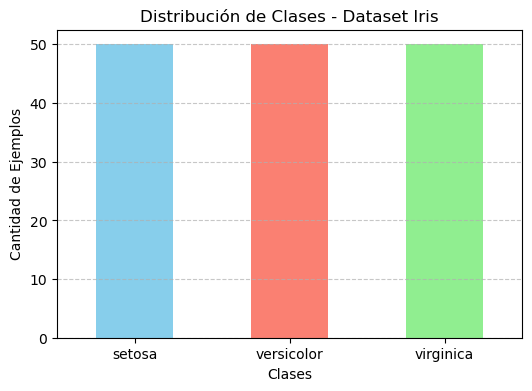

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_iris

# Cargar el dataset Iris
iris = load_iris()

# Crear DataFrame para análisis
# Aqui se hace un mapeo de los valores de la columna "target" a sus nombres correspondientes
df_iris = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df_iris["target"] = iris.target
df_iris["target_name"] = df_iris["target"].map(
    {0: iris.target_names[0], 1: iris.target_names[1], 2: iris.target_names[2]}
)

# Mostrar dimensiones y primeros ejemplos
print(f"Dimensiones X (características): {iris.data.shape}")  # 150 filas (flores) y 4 columnas (medidas)
print(f"Dimensiones y (etiquetas): {iris.target.shape}") # Target y target name guarda valores de la especie de la flor y el nombre de la especie respectivamente
print("\nPrimeros 5 ejemplos:")
display(df_iris.head(5))

# Generar gráfico de distribución
conteo_clases = df_iris["target_name"].value_counts()
plt.figure(figsize=(6, 4))
conteo_clases.plot(kind="bar", color=["skyblue", "salmon", "lightgreen"])
plt.title("Distribución de Clases - Dataset Iris")
plt.xlabel("Clases")
plt.ylabel("Cantidad de Ejemplos")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

## Análisis del Dataset Iris

### 1. Descripción de las instancias y características
- **¿Qué representa cada instancia?:** Cada fila o instancia representa una flor de Iris individual medida de forma independiente.
- **Número de instancias y características:** El dataset contiene un total de **150 instancias** (muestras) y **4 características** descriptivas.
- **Nombre y significado de cada característica (en centímetros):**
  1. `sepal length (cm)`: Longitud del sépalo.
  2. `sepal width (cm)`: Ancho del sépalo.
  3. `petal length (cm)`: Longitud del pétalo.
  4. `petal width (cm)`: Ancho del pétalo.

### 2. Clases y distribución
El problema contempla **3 clases** de flores de Iris:
- `setosa`
- `versicolor`
- `virginica`

Cada clase cuenta exactamente con **50 ejemplos** equilibrados, sumando los 150 registros totales del conjunto de datos, lo que se puede apreciar en el gráfico de distribución de clases.

### 3. Dimensiones de las estructuras
- **Matriz de características ($X$):** `(150, 4)`
- **Vector de etiquetas ($y$):** `(150,)`

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

=== ENTRENAMIENTO Y VALIDACIÓN ===


,Modelo,Accuracy Val,F1 Macro Val
0,Gaussian Naive Bayes,0.933333,0.933333
1,Regresión Logística,0.933333,0.933333
2,SVM Lineal,0.933333,0.933333
3,Árbol de Decisión,0.933333,0.933333
4,Random Forest,0.933333,0.933333
5,Gradient Boosting,0.900000,0.899749
6,MLP de clasificación,0.933333,0.933333



=== EVALUACIÓN FINAL EN PRUEBA (TEST) ===


,Modelo,Accuracy de prueba,F1 macro de prueba
0,Gaussian Naive Bayes,0.9667,0.9666
1,Regresión Logística,0.9333,0.9333
2,SVM Lineal,1.0000,1.0000
3,Árbol de Decisión,0.9333,0.9333
4,Random Forest,0.9000,0.8997
5,Gradient Boosting,0.9667,0.9666
6,MLP de clasificación,0.9667,0.9666


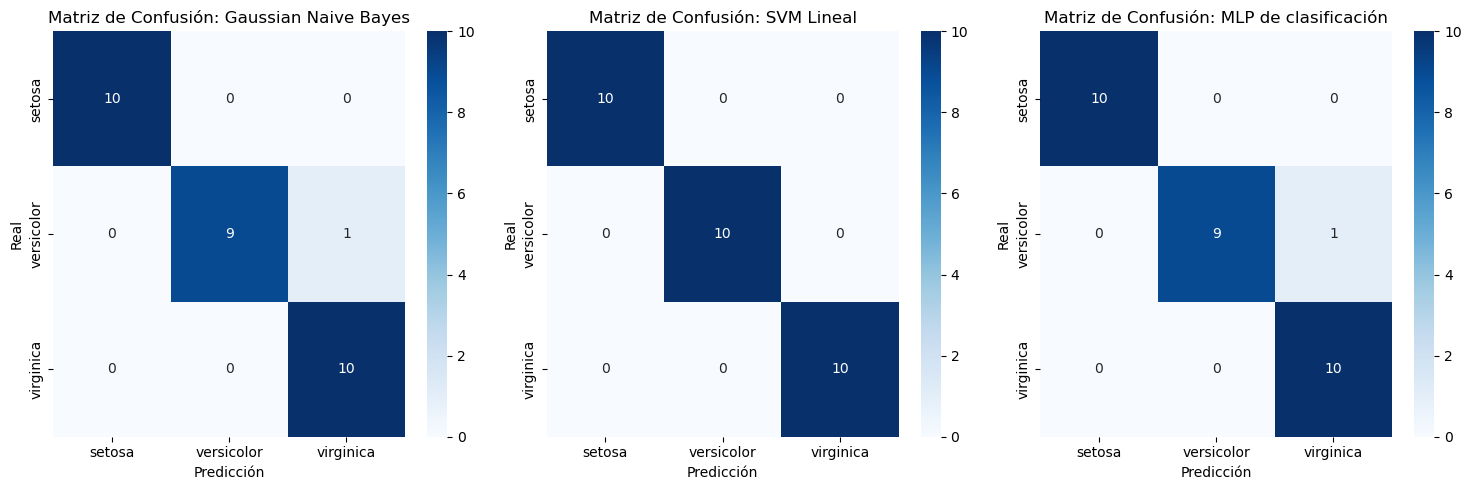

In [ ]:
from sklearn.datasets import load_iris # Importación de la función para cargar el dataset Iris
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier # Importación de los clasificadores de Gradient Boosting y Random Forest
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score # Importación de métricas de evaluación
from sklearn.model_selection import train_test_split # Importación de la función para dividir los datos en conjuntos de entrenamiento, validación y prueba
from sklearn.naive_bayes import GaussianNB # Importación del clasificador Naive Bayes Gaussiano
from sklearn.neighbors import KNeighborsClassifier # Importación del clasificador K-Nearest Neighbors
from sklearn.neural_network import MLPClassifier # Importación del clasificador de redes neuronales MLP
from sklearn.pipeline import make_pipeline # Importación de la función para crear pipelines
from sklearn.preprocessing import StandardScaler # Importación del escalador estándar para normalizar los datos
from sklearn.svm import SVC # Importación del clasificador de máquinas de soporte vectorial (SVM)
from sklearn.tree import DecisionTreeClassifier # Importación del clasificador de árboles de decisión
import matplotlib.pyplot as plt # Importación de la biblioteca para visualización de gráficos
import pandas as pd # Importación de la biblioteca para manipulación de datos
import seaborn as sns # Importación de la biblioteca para visualización de datos

# 1. Cargar y dividir los datos (Train, Validation, Test)
iris = load_iris()
X, y = iris.data, iris.target

# Dividir en entrenamiento+validación (80%) y prueba (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# Dividir train_val en entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val,
)  # 0.25 de 80% = 20% total para validación

# 2. Definir los modelos solicitados (usando Pipeline para estandarizar donde corresponda)
modelos = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=200)),
    "SVM Lineal": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP de clasificación": make_pipeline(StandardScaler(), MLPClassifier(max_iter=500, random_state=42))
}

resultados = []

print("=== ENTRENAMIENTO Y VALIDACIÓN ===")
for nombre, modelo in modelos.items(): # Iterar sobre cada modelo definido
    modelo.fit(X_train, y_train) # Entrenar el modelo con los datos de entrenamiento
    y_pred_val = modelo.predict(X_val) # Predecir las etiquetas para el conjunto de validación
    
    acc = accuracy_score(y_val, y_pred_val) # Calcular la precisión (accuracy) del modelo en el conjunto de validación
    f1 = f1_score(y_val, y_pred_val, average='macro') # Calcular la puntuación F1 macro del modelo en el conjunto de validación
    
    resultados.append({"Modelo": nombre, "Accuracy Val": acc, "F1 Macro Val": f1})

df_resultados = pd.DataFrame(resultados)
display(df_resultados)

# 3. Evaluación final en la partición de prueba con los modelos seleccionados
print("\n=== EVALUACIÓN FINAL EN PRUEBA (TEST) ===")
test_resultados = []
modelos_entrenados = {}

for nombre, modelo in modelos.items():
    # Entrenar con todo el conjunto train_val para la prueba final
    modelo.fit(X_train_val, y_train_val) # Entrenar el modelo con los datos de entrenamiento y validación combinados
    modelos_entrenados[nombre] = modelo # Guardar el modelo entrenado para su uso posterior en la evaluación de prueba
    y_pred_test = modelo.predict(X_test) # Predecir las etiquetas para el conjunto de prueba
    
    acc_test = accuracy_score(y_test, y_pred_test)
    f1_test = f1_score(y_test, y_pred_test, average='macro')
    
    test_resultados.append({ # Guardar los resultados de la evaluación en prueba
        "Modelo": nombre,
        "Accuracy de prueba": round(acc_test, 4),
        "F1 macro de prueba": round(f1_test, 4)
    })

df_test = pd.DataFrame(test_resultados)
display(df_test)

# 4. Matrices de confusión para Naive Bayes, SVM y MLP
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
modelos_a_graficar = ["Gaussian Naive Bayes", "SVM Lineal", "MLP de clasificación"]

for i, nombre in enumerate(modelos_a_graficar):
    modelo = modelos_entrenados[nombre]
    y_pred = modelo.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], 
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    axes[i].set_title(f"Matriz de Confusión: {nombre}")
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Real")

plt.tight_layout()
plt.show()

## 2. Comparación de clasificadores

### Resultados y Evaluación
- **Mejor desempeño en prueba:** El **SVM Lineal** obtuvo un $Accuracy$ y un $F1\text{-}macro$ de `1.0000`, clasificando a la perfección todas las instancias del conjunto de prueba.
- **Modelos sólidos ($0.9667$):** Gaussian Naive Bayes, Gradient Boosting y el Perceptro Multicapa (MLP) alcanzaron un rendimiento sobresaliente, fallando únicamente en una sola instancia.

### Interpretación y Preguntas
1. **¿Cuál fue el modelo con el mejor desempeño?:** El SVM Lineal, al separar de forma óptima las clases linealmente mediante hiperplanos en el espacio transformado.
2. **¿Cuál fue el modelo más sencillo de programar?:** Modelos como Gaussian Naive Bayes o la Regresión Logística, debido a su simplicidad conceptual y bajo requerimiento de hiperparámetros.
3. **¿Accuracy y F1 macro cuentan la misma historia?:** En este dataset sí, debido a que las clases están perfectamente balanceadas (50 ejemplos por clase). Sin embargo, en datasets desbalanceados, el *Accuracy* puede engañar mientras que el $F1\text{-}macro$ penaliza la mala clasificación de clases minoritarias.
4. **¿Cuál es la diferencia entre las métricas macro y micro?:** La métrica *macro* calcula el promedio no ponderado de las métricas de cada clase por separado, dándole la misma importancia a todas. La métrica *micro* agrupa los verdaderos positivos y falsos positivos globales de todas las clases.
5. **¿Qué aporta el MLP frente a un modelo lineal?:** El MLP incorpora capas ocultas con funciones de activación no lineales, lo que le permite aprender fronteras de decisión complejas y no lineales, aunque en un dataset tan linealmente separable como Iris la diferencia frente al modelo lineal es mínima.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

=== EVALUACIÓN DE MODELOS DE REGRESIÓN EN PRUEBA ===


c:\Users\pc\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE,RMSE,R²
0,Regresión lineal,42.79,53.85,0.4526
1,Ridge,46.14,55.47,0.4192
2,Lasso,49.73,58.34,0.3576
3,kNN de regresión,42.78,55.20,0.4248
4,Árbol de regresión,54.53,70.55,0.0607
5,Random Forest de regresión,44.05,54.33,0.4428
6,Gradient Boosting de regresión,44.60,53.84,0.4529
7,MLP de regresión,48.27,61.82,0.2788


c:\Users\pc\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


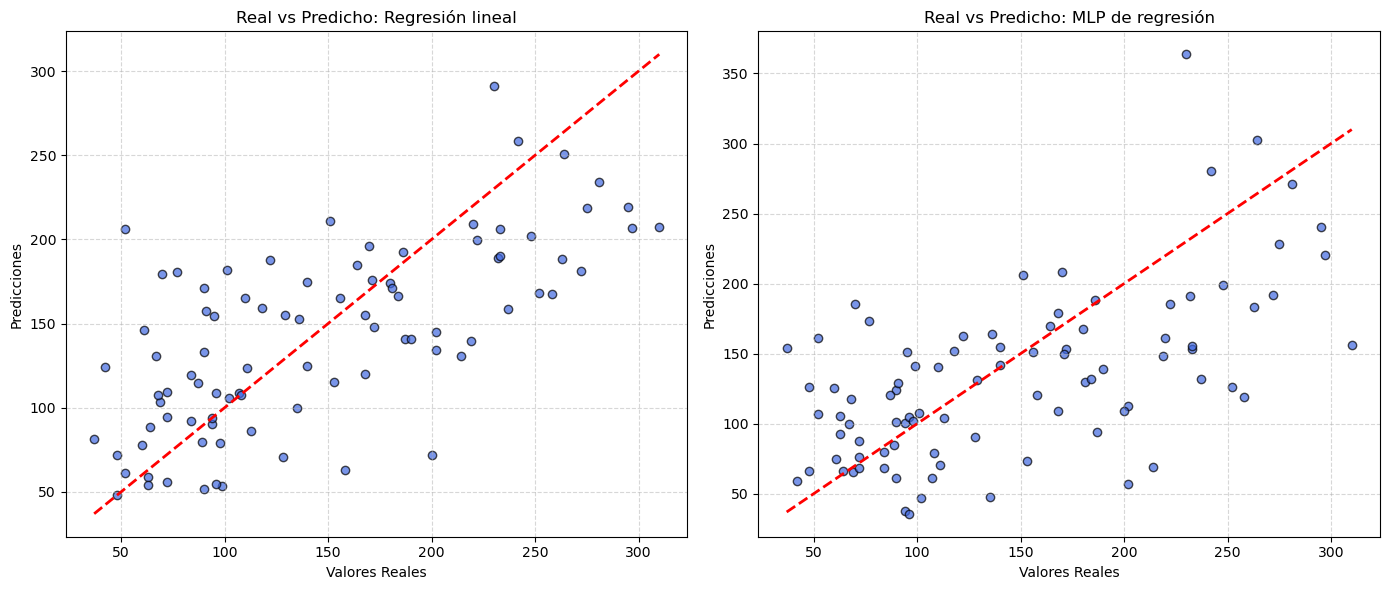

In [ ]:
from sklearn.datasets import load_diabetes # Importación de la función para cargar el dataset Diabetes
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor # Importación de los regresores de Gradient Boosting y Random Forest
from sklearn.linear_model import LinearRegression, Ridge, Lasso # Importación de los regresores lineales (Regresión Lineal, Ridge y Lasso)
from sklearn.neighbors import KNeighborsRegressor # Importación del regresor K-Nearest Neighbors
from sklearn.neural_network import MLPRegressor # Importación del regresor de redes neuronales MLP
from sklearn.tree import DecisionTreeRegressor # Importación del regresor de árboles de decisión
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score # Importación de métricas de evaluación para regresión
from sklearn.model_selection import train_test_split # Importación de la función para dividir los datos en conjuntos de entrenamiento y prueba
from sklearn.pipeline import make_pipeline # Importación de la función para crear pipelines
from sklearn.preprocessing import StandardScaler # Importación del escalador estándar para normalizar los datos
import matplotlib.pyplot as plt # Importación de la biblioteca para visualización de gráficos
import numpy as np # Importación de la biblioteca para operaciones numéricas
import pandas as pd # Importación de la biblioteca para manipulación de datos

# 1. Cargar el dataset Diabetes
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

# Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Definir los modelos de regresión solicitados
modelos_reg = {
    "Regresión lineal": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "kNN de regresión": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "Árbol de regresión": DecisionTreeRegressor(random_state=42),
    "Random Forest de regresión": RandomForestRegressor(random_state=42),
    "Gradient Boosting de regresión": GradientBoostingRegressor(random_state=42),
    "MLP de regresión": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42))
}

resultados_reg = []

print("=== EVALUACIÓN DE MODELOS DE REGRESIÓN EN PRUEBA ===")
for nombre, modelo in modelos_reg.items(): # Iterar sobre cada modelo de regresión definido
    modelo.fit(X_train, y_train) # Entrenar el modelo con los datos de entrenamiento
    y_pred = modelo.predict(X_test) # Predecir las etiquetas para el conjunto de prueba
    
    mae = mean_absolute_error(y_test, y_pred) # Calcular el error absoluto medio (MAE) del modelo en el conjunto de prueba
    rmse = np.sqrt(mean_squared_error(y_test, y_pred)) # Calcular la raíz del error cuadrático medio (RMSE) del modelo en el conjunto de prueba
    r2 = r2_score(y_test, y_pred) # Calcular el coeficiente de determinación (R²) del modelo en el conjunto de prueba
    
    resultados_reg.append({
        "Modelo": nombre,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R²": round(r2, 4)
    })

df_reg = pd.DataFrame(resultados_reg)
display(df_reg)

# 3. Gráficos de Valores Reales vs Predicciones (Regresión Lineal y MLP)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
modelos_grafica = [("Regresión lineal", LinearRegression()), ("MLP de regresión", make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)))]

for i, (nombre, modelo) in enumerate(modelos_grafica):
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    
    axes[i].scatter(y_test, y_pred, color='royalblue', edgecolors='k', alpha=0.7)
    axes[i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[i].set_title(f"Real vs Predicho: {nombre}")
    axes[i].set_xlabel("Valores Reales")
    axes[i].set_ylabel("Predicciones")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Interpretación de Resultados - Regresión (Dataset Diabetes)

1. **¿Qué modelo tuvo el mejor desempeño?:** 
   La **Regresión lineal** y **Gradient Boosting** obtuvieron el mejor desempeño global, alcanzando los valores de $R^2$ más altos (~$0.45$) y los errores (MAE y RMSE) más bajos.

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?:** 
   Porque el MAE promedia los errores de forma lineal (dándole la misma ponderación a todos), mientras que el RMSE eleva los errores al cuadrado antes de promediarlos, castigando severamente a los modelos que cometen fallos catastróficos o desviaciones gigantescas puntuales.

3. **¿Cómo se interpreta un $R^2$ negativo?:** 
   Un $R^2$ negativo indica que el modelo es peor que un modelo ingenuo que simplemente predijera el valor promedio constante de los datos de entrenamiento para cualquier caso nuevo.

4. **¿Qué efecto tuvo aumentar la regularización?:** 
   En modelos lineales como Ridge y Lasso, penalizar los coeficientes grandes ayuda a reducir el sobreajuste (*overfitting*), aunque si la penalización es excesiva puede causar subajuste (*underfitting*), reduciendo ligeramente la capacidad predictiva inicial como se vio en los resultados.

5. **¿Qué puede explicar los errores grandes?:** 
   La presencia de ruido en los datos médicos, factores socioeconómicos o genéticos no contemplados en las 10 características del dataset de diabetes, y la complejidad inherente de la progresión de la enfermedad.

6. **¿Un coeficiente predictivo demuestra una relación causal?:** 
   **No.** Un coeficiente predictivo alto solo demuestra una fuerte **correlación estadística** o asociación matemática entre la variable y el objetivo, pero la correlación no implica causalidad por sí misma.